# **SpaceX  Falcon 9 First Stage Landing Prediction**


## Assignment: Exploring and Preparing Data


Estimated time needed: **70** minutes


In this assignment, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is due to the fact that SpaceX can reuse the first stage.

In this lab, you will perform Exploratory Data Analysis and Feature Engineering.


## Objectives

Perform exploratory Data Analysis and Feature Engineering using `Pandas` and `Matplotlib`

*   Exploratory Data Analysis
*   Preparing Data  Feature Engineering


***


### Import Libraries and Define Auxiliary Functions


We will import the following libraries the lab


In [17]:
# andas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
#NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns

## Exploratory Data Analysis


First, let's read the SpaceX dataset into a Pandas dataframe and print its summary


In [18]:
# Load the SpaceX launch dataset. The alternate IBM Skills Network URL is used if the primary URL is unavailable.
DATA_URLS = [
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv",
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/dataset_part_2.csv",
]
last_error = None
for url in DATA_URLS:
    try:
        df = pd.read_csv(url)
        print(f"Loaded {len(df)} launch records from: {url}")
        break
    except Exception as exc:
        last_error = exc
else:
    raise RuntimeError("Could not download the SpaceX dataset. Check your internet connection or download dataset_part_2.csv and load it locally.") from last_error

df.head()


Loaded 90 launch records from: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the <code>FlightNumber</code> vs. <code>PayloadMass</code>and overlay the outcome of the launch. We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass is also important; it seems the more massive the payload, the less likely the first stage will return.


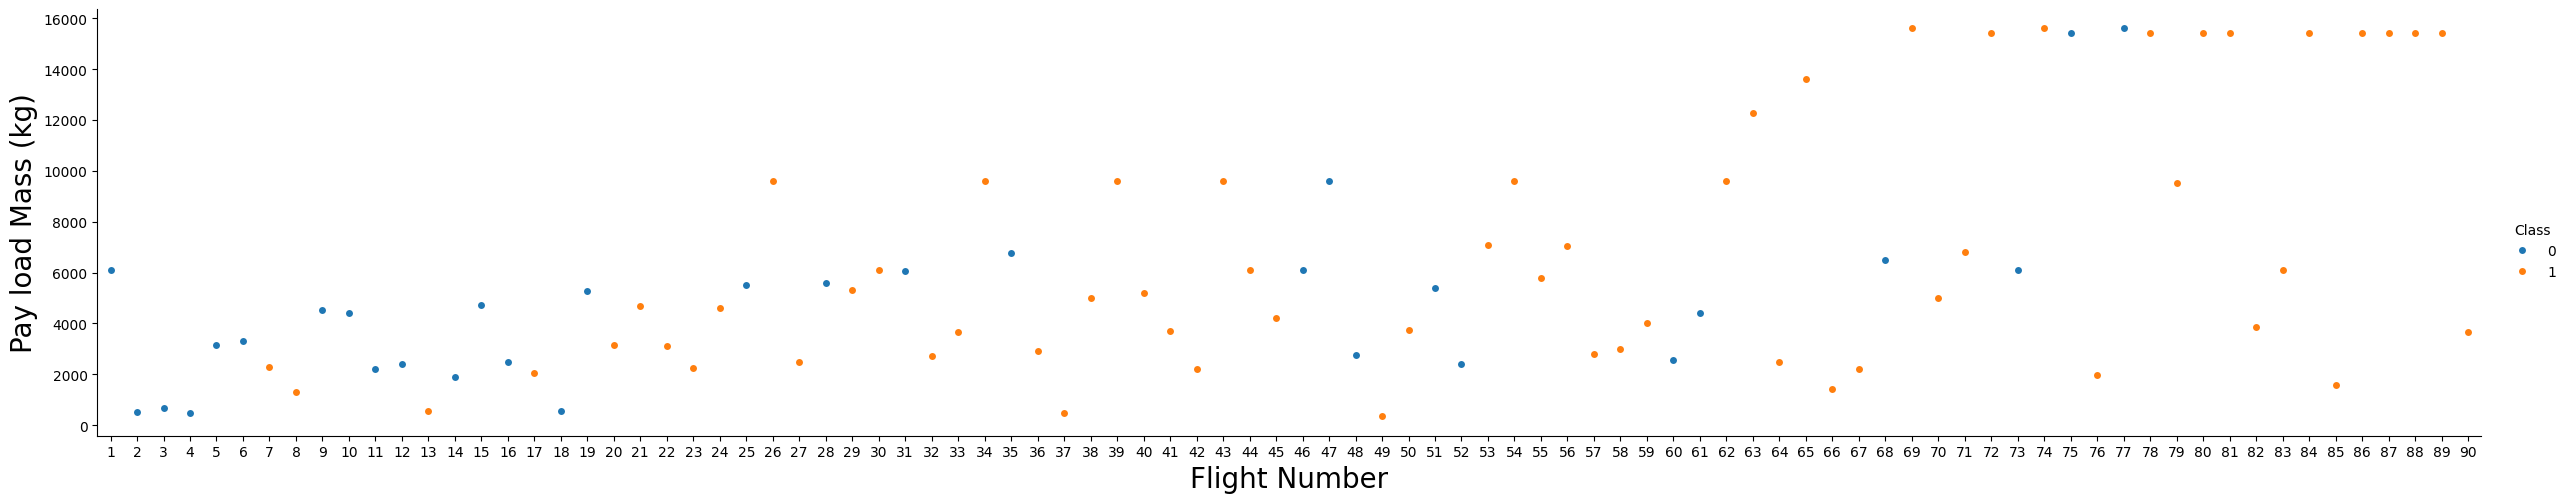

In [19]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect = 5)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Pay load Mass (kg)",fontsize=20)
plt.show()

We see that different launch sites have different success rates.  <code>CCAFS LC-40</code>, has a success rate of 60 %, while  <code>KSC LC-39A</code> and <code>VAFB SLC 4E</code> has a success rate of 77%.


Next, let's drill down to each site visualize its detailed launch records.


### TASK 1: Visualize the relationship between Flight Number and Launch Site


Use the function <code>catplot</code> to plot <code>FlightNumber</code> vs <code>LaunchSite</code>, set the  parameter <code>x</code>  parameter to <code>FlightNumber</code>,set the  <code>y</code> to <code>Launch Site</code> and set the parameter <code>hue</code> to <code>'class'</code>


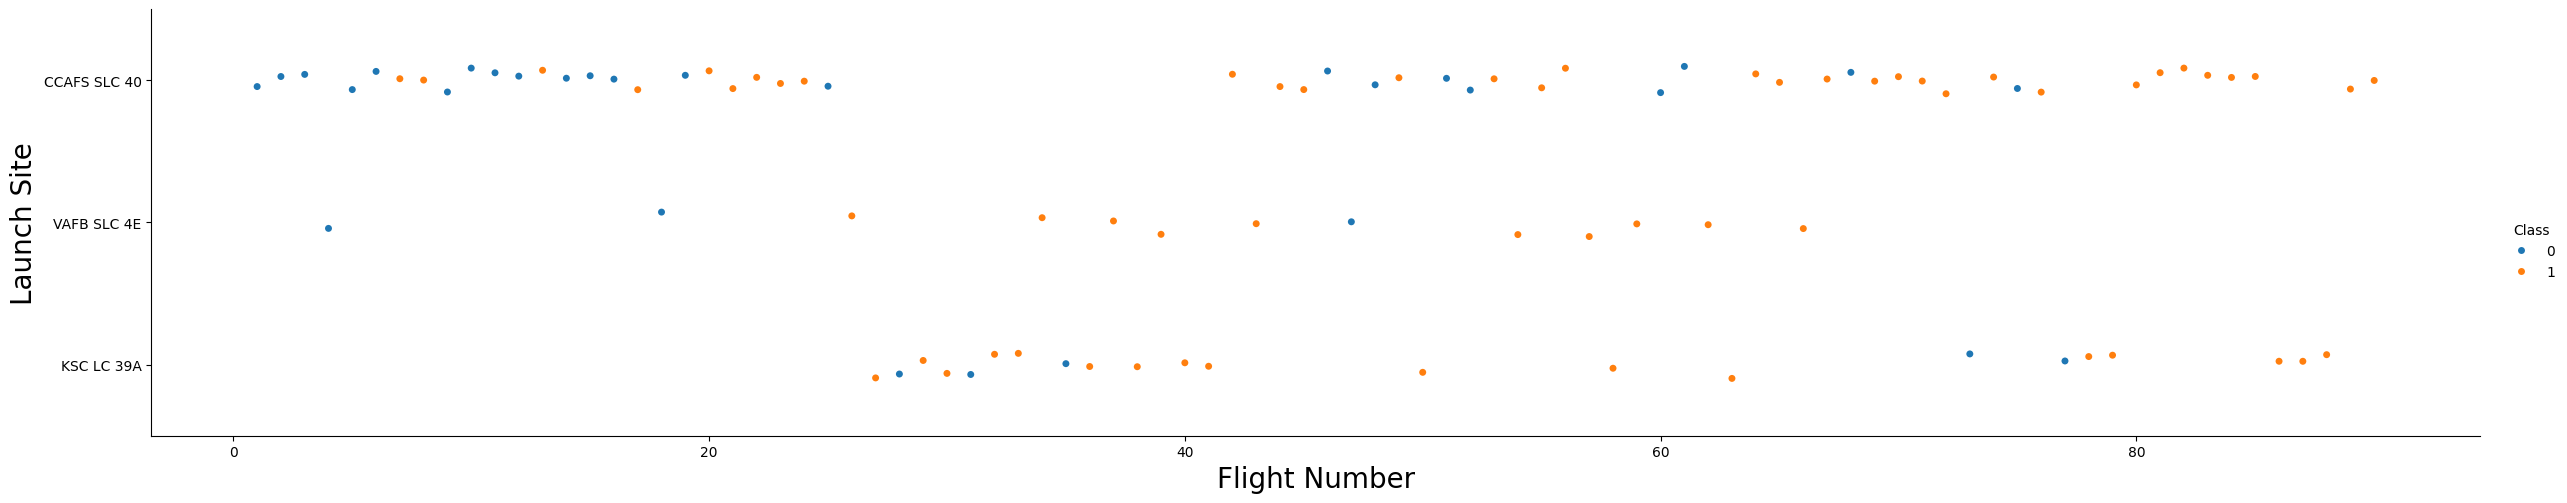

In [20]:
# Plot a scatter point chart with x axis to be Flight Number and y axis to be the launch site, and hue to be the class value
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect = 5)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Launch Site",fontsize=20)
plt.show()

Now try to explain the patterns you found in the Flight Number vs. Launch Site scatter point plots.


### TASK 2: Visualize the relationship between Payload and Launch Site


We also want to observe if there is any relationship between launch sites and their payload mass.


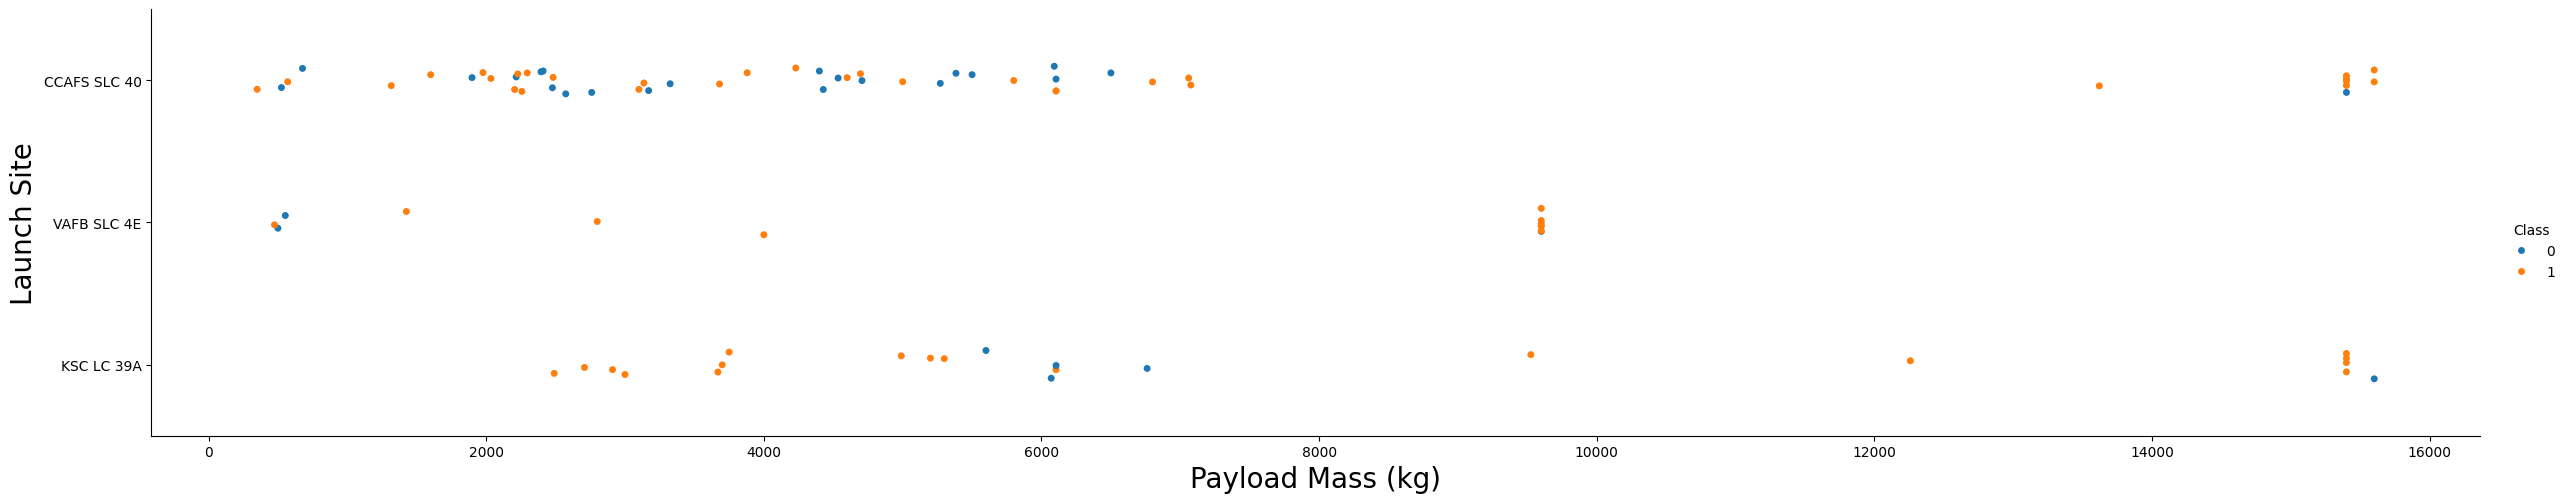

In [21]:
# Plot a scatter point chart with x axis to be Pay Load Mass (kg) and y axis to be the launch site, and hue to be the class value
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect = 5)
plt.xlabel("Payload Mass (kg)",fontsize=20)
plt.ylabel("Launch Site",fontsize=20)
plt.show()

Now try to explain any patterns you found in the Payload Vs. Launch Site scatter point chart.


In [22]:
# Payloads that approach MAX(Payload) tended to launch from CCAFS SLC 40 & KSC LC 39A
# Payloads less than 8000 kg tended to fail at a higher rate when launched from CCAFS SLC 40,
#  plausibly due to that launch site being used for R&D versus the other two launch
#  sites used with less failure-tolerant payloads.

### TASK  3: Visualize the relationship between success rate of each orbit type


Next, we want to visually check if there are any relationship between success rate and orbit type.


Let's create a `bar chart` for the sucess rate of each orbit


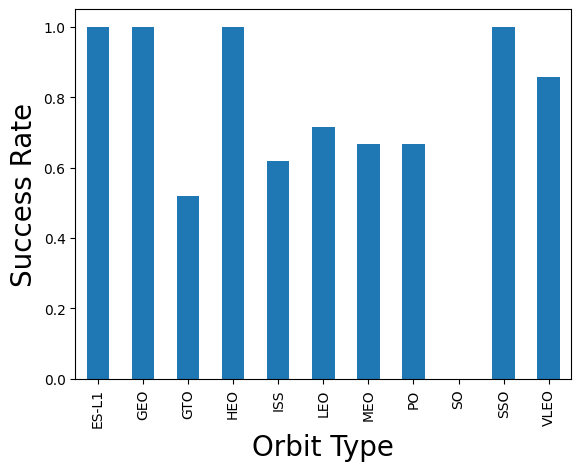

In [24]:
# HINT use groupby method on Orbit column and get the mean of Class column
df.groupby("Orbit")['Class'].mean().plot(kind='bar')
plt.xlabel("Orbit Type",fontsize=20)
plt.ylabel("Success Rate",fontsize=20)
plt.show()

Analyze the ploted bar chart try to find which orbits have high sucess rate.


### TASK  4: Visualize the relationship between FlightNumber and Orbit type


For each orbit, we want to see if there is any relationship between FlightNumber and Orbit type.


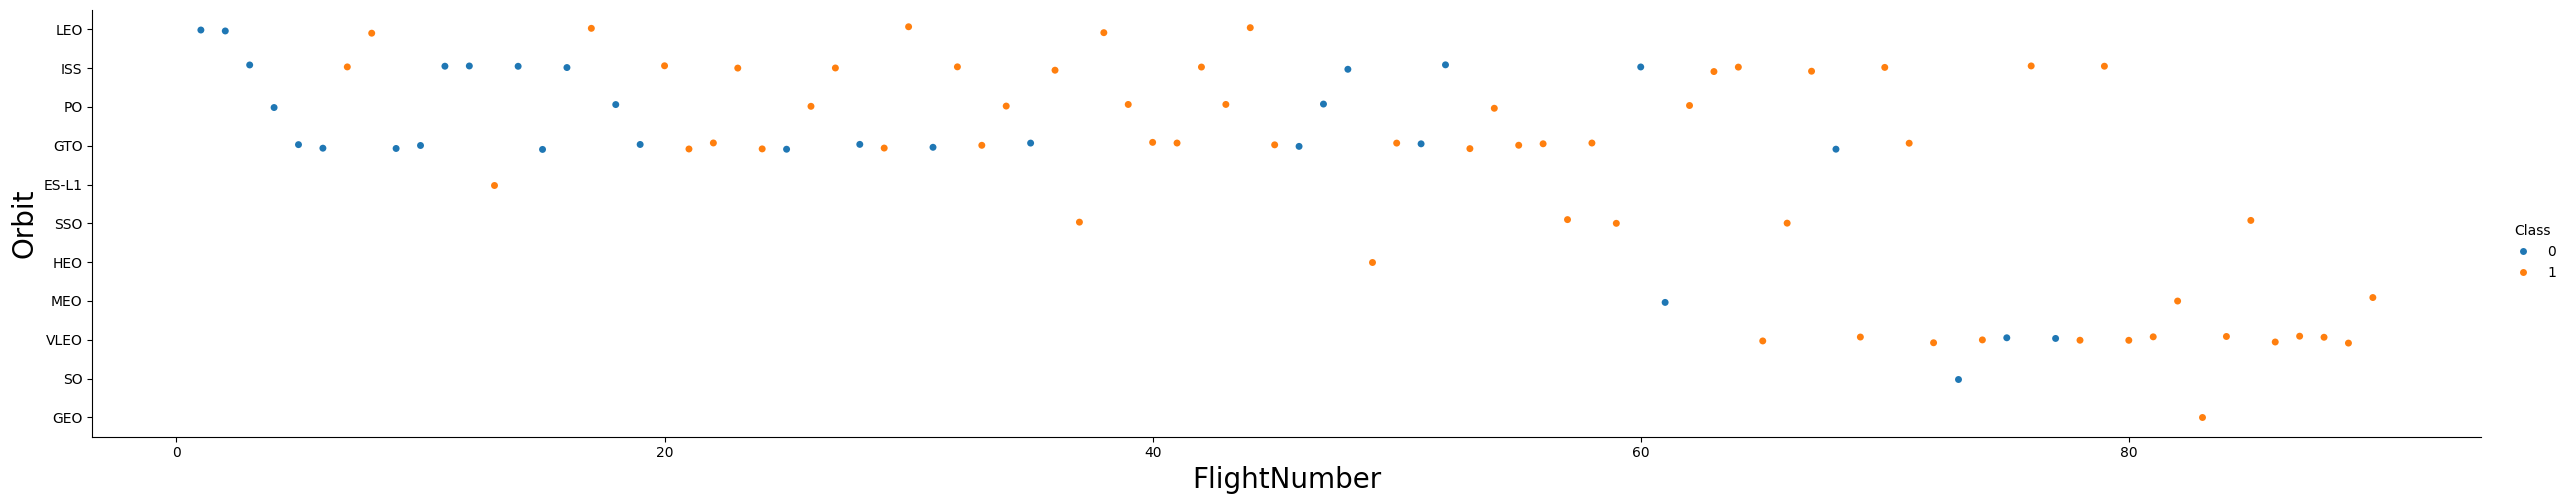

In [25]:
# Plot a scatter point chart with x axis to be FlightNumber and y axis to be the Orbit, and hue to be the class value
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df, aspect = 5)
plt.xlabel("FlightNumber",fontsize=20)
plt.ylabel("Orbit",fontsize=20)
plt.show()

You should see that in the LEO orbit the Success appears related to the number of flights; on the other hand, there seems to be no relationship between flight number when in GTO orbit.


### TASK  5: Visualize the relationship between Payload and Orbit type


Similarly, we can plot the Payload vs. Orbit scatter point charts to reveal the relationship between Payload and Orbit type


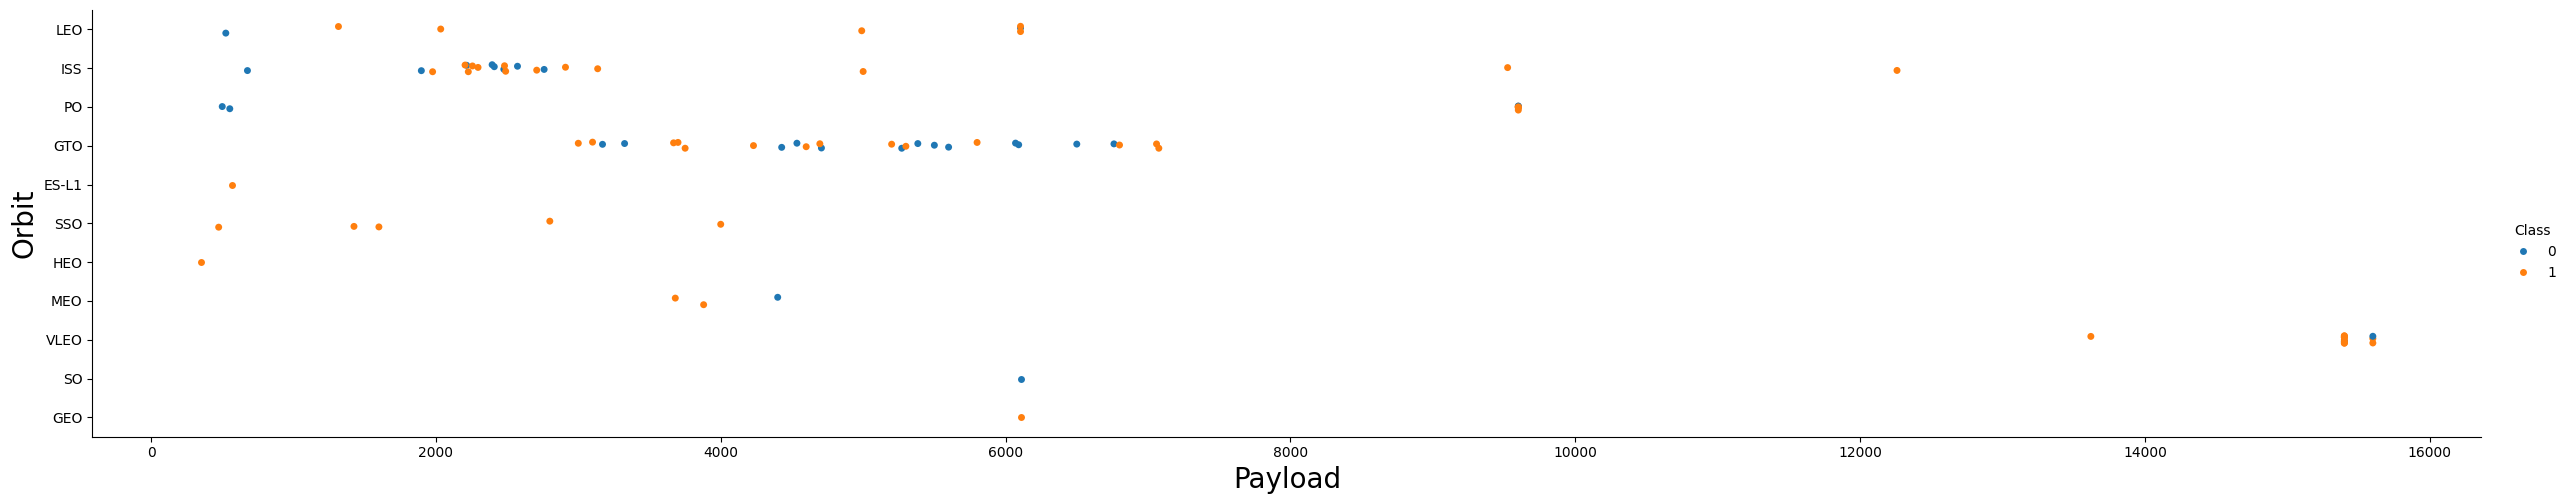

In [26]:
# Plot a scatter point chart with x axis to be Payload and y axis to be the Orbit, and hue to be the class value
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df, aspect = 5)
plt.xlabel("Payload",fontsize=20)
plt.ylabel("Orbit",fontsize=20)
plt.show()

You should observe that Heavy payloads have a negative influence on GTO orbits and positive on GTO and Polar LEO (ISS) orbits.


### TASK  6: Visualize the launch success yearly trend


You can plot a line chart with x axis to be <code>Year</code> and y axis to be average success rate, to get the average launch success trend.


The function will help you get the year from the date:


In [27]:
# Extract the launch year from each date without relying on a global list.
def extract_year(date_series):
    return pd.to_datetime(date_series, errors="coerce").dt.year


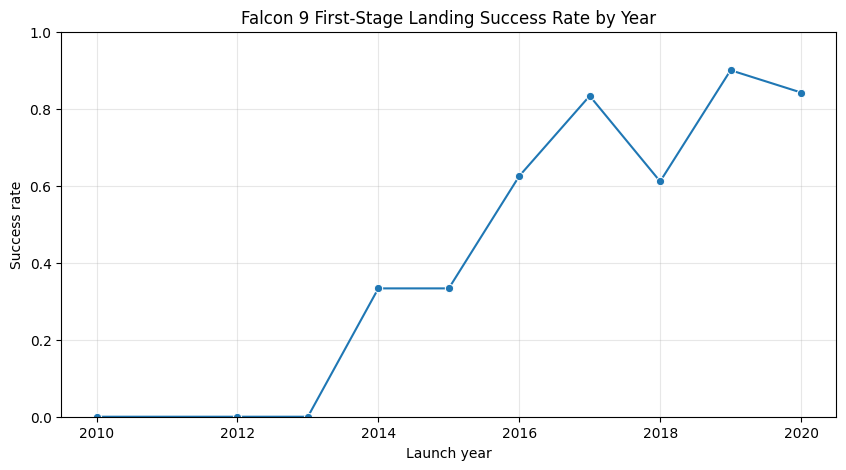

,Year,Class,SuccessRatePercent
0,2010,0.000000,0.0
1,2012,0.000000,0.0
2,2013,0.000000,0.0
3,2014,0.333333,33.3
4,2015,0.333333,33.3
5,2016,0.625000,62.5
6,2017,0.833333,83.3
7,2018,0.611111,61.1
8,2019,0.900000,90.0
9,2020,0.842105,84.2


In [28]:
# Plot annual first-stage landing success rate.
df_year = df[["Date", "Class"]].copy()
df_year["Year"] = extract_year(df_year["Date"])
yearly_success = df_year.groupby("Year", as_index=False)["Class"].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(data=yearly_success, x="Year", y="Class", marker="o")
plt.title("Falcon 9 First-Stage Landing Success Rate by Year")
plt.xlabel("Launch year")
plt.ylabel("Success rate")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()
yearly_success.assign(SuccessRatePercent=(yearly_success["Class"] * 100).round(1))


you can observe that the sucess rate since 2013 kept increasing till 2020


## Features Engineering


By now, you should obtain some preliminary insights about how each important variable would affect the success rate, we will select the features that will be used in success prediction in the
future module.


In [29]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


### TASK  7: Create dummy variables to categorical columns


Use the function <code>get_dummies</code> and <code>features</code> dataframe to apply OneHotEncoder to the column <code>Orbits</code>, <code>LaunchSite</code>, <code>LandingPad</code>, and <code>Serial</code>. Assign the value to the variable <code>features_one_hot</code>, display the results using the method head. Your result dataframe must include all features including the encoded ones.


In [30]:
# HINT: Use get_dummies() function on the categorical columns
features_one_hot = pd.get_dummies(features, columns = ['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


### TASK  8: Cast all numeric columns to `float64`


Now that our <code>features_one_hot</code> dataframe only contains numbers cast the entire dataframe to variable type <code>float64</code>


In [31]:
# Ensure the one-hot encoded feature matrix contains numeric values.
features_one_hot = features_one_hot.astype("float64")
features_one_hot.dtypes.value_counts()


,count
float64,80


We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range.


<code>features_one_hot.to_csv('dataset_part\_3.csv', index=False)</code>


---
# Final Capstone: SQL Analysis, Folium Mapping, and Machine Learning

This section completes the analytical workflow in this same notebook. It uses the dataset loaded above, produces actual query result tables, creates a Folium launch-site map and proximity analysis, and trains/evaluates multiple classifiers. **Run the notebook from top to bottom in an internet-enabled Python environment** so the dataset can be loaded and the result cells populated. Metrics are computed from the dataset at runtime; no model scores are hard-coded.

## 1. Data quality and target definition

`Class = 1` represents a successful first-stage landing and `Class = 0` represents an unsuccessful landing. The target column and identifiers/outcome fields are excluded from the predictors to reduce target leakage.

In [32]:
# Imports used by the final analysis section
import sqlite3
import itertools
import math
import warnings
warnings.filterwarnings("ignore")

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance

# Standardize column labels for downstream analysis while retaining the original dataframe.
print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
print("Missing values in key columns:")
display(df[[c for c in ["Class", "LaunchSite", "PayloadMass", "Orbit", "Date"] if c in df.columns]].isna().sum().to_frame("missing_count"))
print("Target distribution:")
display(df["Class"].value_counts(dropna=False).rename_axis("Class").to_frame("Launches"))


Dataset shape: (90, 18)
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']
Missing values in key columns:


,missing_count
Class,0
LaunchSite,0
PayloadMass,0
Orbit,0
Date,0


Target distribution:


,Launches
Class,
1,60
0,30


## 2. SQL analysis and result tables

SQLite is used to execute real SQL queries against the loaded dataset. These outputs are generated directly from the notebook data, rather than being example query patterns.

In [33]:
# Load the dataframe into an in-memory SQLite table and execute SQL queries.
sql_df = df.copy()
sql_df.to_sql("spacex_launches", sqlite3.connect(":memory:"), if_exists="replace", index=False)
# Keep a persistent in-memory connection for all queries below.
conn = sqlite3.connect(":memory:")
sql_df.to_sql("spacex_launches", conn, if_exists="replace", index=False)

def run_sql(query):
    print(query.strip())
    result = pd.read_sql_query(query, conn)
    display(result)
    return result

sql_site_success = run_sql("""
SELECT LaunchSite,
       COUNT(*) AS total_launches,
       SUM(CASE WHEN Class = 1 THEN 1 ELSE 0 END) AS successful_landings,
       ROUND(100.0 * AVG(Class), 2) AS success_rate_percent
FROM spacex_launches
GROUP BY LaunchSite
ORDER BY success_rate_percent DESC;
""")

sql_orbit_success = run_sql("""
SELECT Orbit,
       COUNT(*) AS total_launches,
       ROUND(100.0 * AVG(Class), 2) AS success_rate_percent,
       ROUND(AVG(PayloadMass), 1) AS average_payload_kg
FROM spacex_launches
GROUP BY Orbit
ORDER BY success_rate_percent DESC;
""")

sql_yearly = run_sql("""
SELECT CAST(substr(Date, 1, 4) AS INTEGER) AS launch_year,
       COUNT(*) AS total_launches,
       ROUND(100.0 * AVG(Class), 2) AS success_rate_percent
FROM spacex_launches
WHERE Date IS NOT NULL
GROUP BY launch_year
ORDER BY launch_year;
""")

sql_payload = run_sql("""
SELECT CASE WHEN PayloadMass < 5000 THEN '< 5,000 kg'
            WHEN PayloadMass < 10000 THEN '5,000–9,999 kg'
            ELSE '10,000+ kg' END AS payload_band,
       COUNT(*) AS total_launches,
       ROUND(100.0 * AVG(Class), 2) AS success_rate_percent
FROM spacex_launches
WHERE PayloadMass IS NOT NULL
GROUP BY payload_band
ORDER BY MIN(PayloadMass);
""")


SELECT LaunchSite,
       COUNT(*) AS total_launches,
       SUM(CASE WHEN Class = 1 THEN 1 ELSE 0 END) AS successful_landings,
       ROUND(100.0 * AVG(Class), 2) AS success_rate_percent
FROM spacex_launches
GROUP BY LaunchSite
ORDER BY success_rate_percent DESC;


,LaunchSite,total_launches,successful_landings,success_rate_percent
0,KSC LC 39A,22,17,77.27
1,VAFB SLC 4E,13,10,76.92
2,CCAFS SLC 40,55,33,60.00


SELECT Orbit,
       COUNT(*) AS total_launches,
       ROUND(100.0 * AVG(Class), 2) AS success_rate_percent,
       ROUND(AVG(PayloadMass), 1) AS average_payload_kg
FROM spacex_launches
GROUP BY Orbit
ORDER BY success_rate_percent DESC;


,Orbit,total_launches,success_rate_percent,average_payload_kg
0,SSO,5,100.00,2060.0
1,HEO,1,100.00,350.0
2,GEO,1,100.00,6105.0
3,ES-L1,1,100.00,570.0
4,VLEO,14,85.71,15315.7
5,LEO,7,71.43,3882.8
6,PO,9,66.67,7583.7
7,MEO,3,66.67,3987.0
8,ISS,21,61.90,3279.9
9,GTO,27,51.85,5012.0


SELECT CAST(substr(Date, 1, 4) AS INTEGER) AS launch_year,
       COUNT(*) AS total_launches,
       ROUND(100.0 * AVG(Class), 2) AS success_rate_percent
FROM spacex_launches
WHERE Date IS NOT NULL
GROUP BY launch_year
ORDER BY launch_year;


,launch_year,total_launches,success_rate_percent
0,2010,1,0.00
1,2012,1,0.00
2,2013,3,0.00
3,2014,6,33.33
4,2015,6,33.33
5,2016,8,62.50
6,2017,18,83.33
7,2018,18,61.11
8,2019,10,90.00
9,2020,19,84.21


SELECT CASE WHEN PayloadMass < 5000 THEN '< 5,000 kg'
            WHEN PayloadMass < 10000 THEN '5,000–9,999 kg'
            ELSE '10,000+ kg' END AS payload_band,
       COUNT(*) AS total_launches,
       ROUND(100.0 * AVG(Class), 2) AS success_rate_percent
FROM spacex_launches
WHERE PayloadMass IS NOT NULL
GROUP BY payload_band
ORDER BY MIN(PayloadMass);


,payload_band,total_launches,success_rate_percent
0,"< 5,000 kg",47,63.83
1,"5,000–9,999 kg",28,60.71
2,"10,000+ kg",15,86.67


## 3. Folium launch-site map and proximity analysis

The dataset contains launch coordinates for individual launch records. The map below places a marker at each available record coordinate and colors the marker by landing outcome. The proximity table computes great-circle distances between the mean coordinates of launch-site records; treat these as dataset-derived approximations, not surveyed facility coordinates.

In [47]:

# Create an interactive launch-site map without external map tiles.
# This avoids OpenStreetMap 403 / tile-access-blocked errors.

import pandas as pd
import math
import itertools
import folium
from IPython.display import display

map_df = df.dropna(
    subset=["Latitude", "Longitude", "LaunchSite"]
).copy()

map_df["Latitude"] = pd.to_numeric(map_df["Latitude"], errors="coerce")
map_df["Longitude"] = pd.to_numeric(map_df["Longitude"], errors="coerce")

map_df = map_df.dropna(subset=["Latitude", "Longitude"])

if not map_df.empty:
    center = [
        map_df["Latitude"].mean(),
        map_df["Longitude"].mean()
    ]

    # No external tile provider: avoids blocked tile requests.
    launch_map = folium.Map(
        location=center,
        zoom_start=4,
        tiles=None
    )

    for _, row in map_df.iterrows():
        landed = int(row["Class"]) == 1

        popup = (
            f"Launch site: {row['LaunchSite']}<br>"
            f"Flight: {row.get('FlightNumber', 'N/A')}<br>"
            f"Outcome: {'Successful landing' if landed else 'Unsuccessful landing'}<br>"
            f"Payload: {row.get('PayloadMass', float('nan'))} kg"
        )

        folium.CircleMarker(
            location=[row["Latitude"], row["Longitude"]],
            radius=6,
            color="green" if landed else "red",
            fill=True,
            fill_color="green" if landed else "red",
            fill_opacity=0.8,
            popup=folium.Popup(popup, max_width=100),
            tooltip=f"{row['LaunchSite']} - "
                    f"{'Successful' if landed else 'Unsuccessful'}"
        ).add_to(launch_map)

    # Automatically frame all launch locations.
    bounds = map_df[["Latitude", "Longitude"]].values.tolist()
    launch_map.fit_bounds(bounds)

    print("Interactive launch-site map:")
    display(launch_map)

    print("Legend: Green = Successful landing | Red = Unsuccessful landing")

else:
    print(
        "No valid Latitude/Longitude values were found. "
        "Check the dataset coordinates."
    )


# Calculate approximate distances between launch-site coordinate centers.
def haversine_km(lat1, lon1, lat2, lon2):
    radius_km = 6371.0088

    p1 = math.radians(lat1)
    p2 = math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)

    a = (
        math.sin(dphi / 2) ** 2
        + math.cos(p1) * math.cos(p2)
        * math.sin(dlambda / 2) ** 2
    )

    a = min(1.0, max(0.0, a))

    return 2 * radius_km * math.asin(math.sqrt(a))


site_centers = (
    map_df.groupby("LaunchSite", as_index=False)
    .agg(
        latitude=("Latitude", "mean"),
        longitude=("Longitude", "mean")
    )
)

proximity_rows = []

for (_, a), (_, b) in itertools.combinations(
    site_centers.iterrows(), 2
):
    proximity_rows.append({
        "launch_site_1": a["LaunchSite"],
        "launch_site_2": b["LaunchSite"],
        "approx_distance_km": round(
            haversine_km(
                a["latitude"], a["longitude"],
                b["latitude"], b["longitude"]
            ),
            2
        )
    })

proximity_df = pd.DataFrame(
    proximity_rows,
    columns=[
        "launch_site_1",
        "launch_site_2",
        "approx_distance_km"
    ]
)

if not proximity_df.empty:
    proximity_df = proximity_df.sort_values(
        "approx_distance_km"
    )

print("\nLaunch-site coordinate centers:")
display(site_centers)

print("\nNearest launch-site pairs by approximate distance (km):")
display(proximity_df.head(10))


Interactive launch-site map:


Legend: Green = Successful landing | Red = Unsuccessful landing

Launch-site coordinate centers:


,LaunchSite,latitude,longitude
0,CCAFS SLC 40,28.561857,-80.577366
1,KSC LC 39A,28.608059,-80.603956
2,VAFB SLC 4E,34.632093,-120.610829



Nearest launch-site pairs by approximate distance (km):


,launch_site_1,launch_site_2,approx_distance_km
0,CCAFS SLC 40,KSC LC 39A,5.76
2,KSC LC 39A,VAFB SLC 4E,3821.64
1,CCAFS SLC 40,VAFB SLC 4E,3825.87


## 4. Predictive modelling: train/test split and model comparison

The workflow uses a stratified hold-out test set, preprocessing fitted only on training data, and four classifier families plus a Random Forest baseline. Categorical columns are one-hot encoded; numeric columns are median-imputed and scaled. Model selection is based on **test-set F1-score**, with accuracy, precision, recall, and a confusion matrix also reported. The selected model is the best-performing candidate on this split, not a universal best model.

In [35]:
# Prepare the prediction target and leakage-safe feature matrix.
model_df = df.copy()
model_df = model_df[model_df["Class"].notna()].copy()
y = model_df["Class"].astype(int)

# Use launch-time predictors only; exclude target, observed outcome, and free-text date.
preferred_features = ["FlightNumber", "PayloadMass", "Orbit", "LaunchSite", "Flights",
                      "GridFins", "Reused", "Legs", "Block", "ReusedCount", "Serial", "BoosterVersion"]
feature_cols = [c for c in preferred_features if c in model_df.columns]
X = model_df[feature_cols].copy()
if not feature_cols:
    raise ValueError("No expected predictor columns were found in the dataset.")

# Normalize boolean columns into numeric values before preprocessing.
for col in X.columns:
    if X[col].dtype == "bool":
        X[col] = X[col].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:  # scikit-learn versions before 1.2
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", encoder)
])
transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_transformer, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_transformer, categorical_features))
preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)} | Predictors: {feature_cols}")

models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Support Vector Machine": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)
}

fitted_models = {}
results = []
predictions = {}
for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[("preprocess", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    fitted_models[model_name] = pipeline
    predictions[model_name] = pred
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

model_results = pd.DataFrame(results).sort_values(["F1-score", "Accuracy"], ascending=False).reset_index(drop=True)
print("Model comparison on the held-out test set:")
display(model_results.style.format({"Accuracy":"{:.3f}", "Precision":"{:.3f}", "Recall":"{:.3f}", "F1-score":"{:.3f}"}))
best_model_name = model_results.loc[0, "Model"]
best_model = fitted_models[best_model_name]
best_predictions = predictions[best_model_name]
print("Best model by test F1-score:", best_model_name)


Training rows: 67 | Test rows: 23 | Predictors: ['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Serial', 'BoosterVersion']
Model comparison on the held-out test set:


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.870,0.875,0.933,0.903
1,Logistic Regression,0.826,0.789,1.000,0.882
2,K-Nearest Neighbors,0.826,0.789,1.000,0.882
3,Random Forest,0.826,0.824,0.933,0.875
4,Support Vector Machine,0.783,0.778,0.933,0.848


Best model by test F1-score: Decision Tree


## 5. Confusion matrix and classification report for the selected model

The confusion matrix shows true negatives, false positives, false negatives, and true positives for the model selected by test F1-score. The classification report provides class-level precision, recall, and F1-score.

Selected model: Decision Tree
Confusion matrix (rows = actual [0, 1], columns = predicted [0, 1]):
[[ 6  2]
 [ 1 14]]

Classification report:
                          precision    recall  f1-score   support

Unsuccessful landing (0)       0.86      0.75      0.80         8
  Successful landing (1)       0.88      0.93      0.90        15

                accuracy                           0.87        23
               macro avg       0.87      0.84      0.85        23
            weighted avg       0.87      0.87      0.87        23



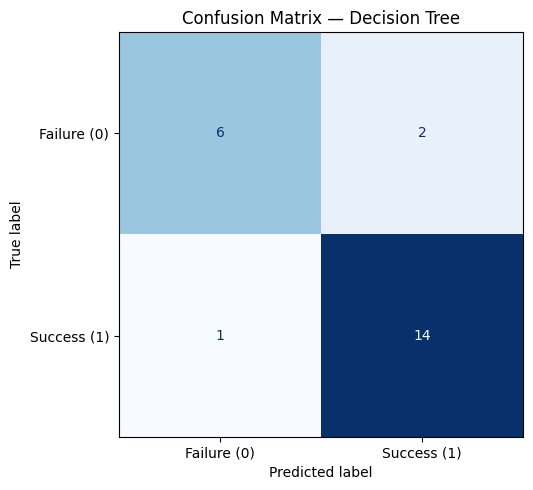

In [36]:
cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])
print("Selected model:", best_model_name)
print("Confusion matrix (rows = actual [0, 1], columns = predicted [0, 1]):")
print(cm)
print("\nClassification report:")
print(classification_report(y_test, best_predictions, labels=[0, 1], target_names=["Unsuccessful landing (0)", "Successful landing (1)"], zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Failure (0)", "Success (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


## 6. Feature influence and probability interpretation

Permutation importance measures how much the selected model's F1-score decreases when one input column is shuffled. It is model-agnostic and works with the full preprocessing pipeline. Importance is predictive association, not proof of causation.

,Feature,Mean F1 decrease,Std. deviation
9,ReusedCount,0.120979,0.060399
5,GridFins,0.074563,0.014692
7,Legs,0.059576,0.015289
1,PayloadMass,0.047460,0.033374
4,Flights,0.007312,0.014624
10,Serial,0.003656,0.010968
0,FlightNumber,0.000000,0.000000
2,Orbit,0.000000,0.000000
3,LaunchSite,0.000000,0.000000
6,Reused,0.000000,0.000000


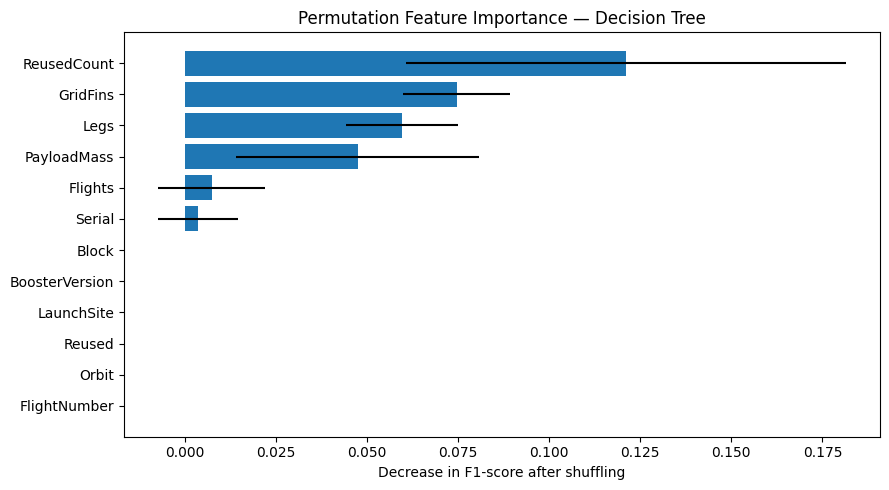

Example held-out predictions with estimated landing-success probability:


,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,Block,ReusedCount,Serial,BoosterVersion,ActualClass,PredictedClass,PredictedSuccessProbability
12,13,570.0,ES-L1,CCAFS SLC 40,1,1,0,1,1.0,0,B1013,Falcon 9,1,0,0.0
13,14,1898.0,ISS,CCAFS SLC 40,1,1,0,1,1.0,0,B1015,Falcon 9,0,0,0.0
33,34,9600.0,PO,VAFB SLC 4E,1,1,0,1,3.0,1,B1036,Falcon 9,1,1,1.0
46,47,9600.0,PO,VAFB SLC 4E,2,1,1,1,4.0,1,B1041,Falcon 9,0,1,1.0
8,9,4535.0,GTO,CCAFS SLC 40,1,0,0,0,1.0,0,B1008,Falcon 9,0,0,0.0
81,82,3880.0,MEO,CCAFS SLC 40,1,1,0,1,5.0,2,B1060,Falcon 9,1,1,1.0
34,35,6761.0,GTO,KSC LC 39A,1,0,0,0,3.0,0,B1037,Falcon 9,0,0,0.0
80,81,15400.0,VLEO,CCAFS SLC 40,3,1,1,1,5.0,3,B1059,Falcon 9,1,1,1.0
49,50,3750.0,GTO,KSC LC 39A,1,1,0,1,5.0,3,B1046,Falcon 9,1,1,1.0
36,37,475.0,SSO,VAFB SLC 4E,1,1,0,1,3.0,1,B1038,Falcon 9,1,1,1.0


In [37]:
# Permutation importance on held-out data. This uses original columns, so the results are easy to explain.
perm = permutation_importance(
    best_model, X_test, y_test, scoring="f1", n_repeats=10, random_state=42, n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean F1 decrease": perm.importances_mean,
    "Std. deviation": perm.importances_std
}).sort_values("Mean F1 decrease", ascending=False)
display(importance_df)

plt.figure(figsize=(9, 5))
plot_importance = importance_df.sort_values("Mean F1 decrease", ascending=True)
plt.barh(plot_importance["Feature"], plot_importance["Mean F1 decrease"], xerr=plot_importance["Std. deviation"])
plt.xlabel("Decrease in F1-score after shuffling")
plt.title(f"Permutation Feature Importance — {best_model_name}")
plt.tight_layout()
plt.show()

# Show probabilities when the chosen estimator supports predict_proba.
if hasattr(best_model, "predict_proba"):
    predicted_probability = best_model.predict_proba(X_test)[:, 1]
    probability_results = X_test.copy()
    probability_results["ActualClass"] = y_test.to_numpy()
    probability_results["PredictedClass"] = best_predictions
    probability_results["PredictedSuccessProbability"] = predicted_probability.round(3)
    print("Example held-out predictions with estimated landing-success probability:")
    display(probability_results.head(10))
else:
    print("The selected estimator does not expose calibrated class probabilities.")


## 7. Final evidence-based conclusion

After running all cells, use the generated SQL tables, Folium map, proximity table, model comparison, and confusion matrix as the evidence for the presentation. Report the **computed** winning model and metrics shown above. Do not copy values from a different run, and do not interpret feature importance as causation. The held-out test set is small, so model ranking can vary with the split; a production system would need cross-validation, more recent launch records, calibration, and external validation.

In [38]:
# Compact, reproducible summary table for the final report.
summary = {
    "Dataset rows used for modelling": int(len(model_df)),
    "Training rows": int(len(X_train)),
    "Test rows": int(len(X_test)),
    "Predictor count": int(len(feature_cols)),
    "Best model by test F1": best_model_name,
    "Accuracy": round(float(accuracy_score(y_test, best_predictions)), 4),
    "Precision": round(float(precision_score(y_test, best_predictions, zero_division=0)), 4),
    "Recall": round(float(recall_score(y_test, best_predictions, zero_division=0)), 4),
    "F1-score": round(float(f1_score(y_test, best_predictions, zero_division=0)), 4),
}
display(pd.DataFrame([summary]).T.rename(columns={0: "Value"}))


,Value
Dataset rows used for modelling,90
Training rows,67
Test rows,23
Predictor count,12
Best model by test F1,Decision Tree
Accuracy,0.8696
Precision,0.875
Recall,0.9333
F1-score,0.9032
